# 독성 모델 최종 개선: 확률 스태킹·전량 재학습·미세조정

목표는 리더보드 비독성 F1 0.85 이상이다. OOF와 리더보드의 차이를 고정 가산하지 않는다. 기존 3차 Output·데이터·07_개선·09_임계값은 보존했다. 자동 제출하지 않았다.

이 노트북은 완료된 로컬 실험을 읽고 비교·검증한다. 긴 학습을 자동으로 다시 실행하지 않는다.

In [1]:
from pathlib import Path
import os,sys,json,hashlib,tempfile
os.environ.setdefault('MPLCONFIGDIR',str(Path(tempfile.gettempdir())/'toxicity-matplotlib'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import f1_score,roc_auc_score
cwd=Path.cwd().resolve()
ROOT=next(p for p in [cwd,*cwd.parents,*[x for x in cwd.iterdir() if x.is_dir()]] if (p/'02_데이터/train.csv').exists())
DEST=ROOT/'10_최종개선'
validation=json.loads((DEST/'validation.json').read_text())
selection=json.loads((DEST/'final_selection.json').read_text())
for path,digest in json.loads((DEST/'protected_hashes.json').read_text()).items():
 assert hashlib.sha256((ROOT/path).read_bytes()).hexdigest()==digest
print('PASS: 기존 3차 Output·데이터·클로드 코드/캐시 보존')
print(validation)

PASS: 기존 3차 Output·데이터·클로드 코드/캐시 보존
{'rows': 927, 'columns': ['SMILES', 'output'], 'SMILES_order_exact': True, 'binary_output': True, 'label_1': 'safe/nontoxic', 'all_protected_sources_unchanged': True, 'OOF_replay_exact': True, 'predictions_match_frozen_cutoff': True, 'submission_sha256': '4a0317ff663a712f4d762e5ee8af5e369f8347baef1e8b35fcb1a35ad544c421', 'submitted': False}


## 1. 클로드 작업 재현과 검증 한계

기존 16개 입력을 다시 읽고 같은 로지스틱 스택과 D=567을 재현했다. 파생 `final_stack_lr`는 입력에서 제외한다. 이 파일을 다시 입력에 넣으면 자기 스태킹이 된다.

기존 "nested" 검증은 메타 모델과 임계값만 분리한다. base OOF 생성 모델 중에는 outer 메타 검증 라벨을 본 모델이 있으므로 간접 누수가 가능하다. 이번 학습량 비교에서는 base부터 inner fold로 다시 학습해 outer 라벨이 실제 fitting에 들어가지 않도록 했다. 이전 전체 CV로 하이퍼파라미터를 고른 한계는 남아 있다.

In [2]:
audit=json.loads((DEST/'claude_audit.json').read_text())
print(json.dumps(audit,ensure_ascii=False,indent=2))
assert audit['current_output_reproduced'] and audit['oof_reproduction_max_abs_difference']==0
meta=pd.read_csv(DEST/'boundary_meta_comparison.csv')
display(meta[['name','auc','repeated_cross_threshold_f1','band_auc','band_accuracy']])
print('추가 6개 모델의 불확실성:',json.loads((DEST/'meta_gain_uncertainty.json').read_text()))

{
  "pool": [
    "bag_cp",
    "bag_gbdt_all",
    "bag_lgb_fp2",
    "cat_fp2",
    "et",
    "knn_tan",
    "lgb_mord",
    "lgb_mordonly",
    "logit_bin",
    "mlp",
    "rf",
    "svm_cb77",
    "svm_mk_p2_c3",
    "svm_molf",
    "svm_tani10",
    "xgb_fp2"
  ],
  "oof_reproduction_max_abs_difference": 0.0,
  "test_reproduction_max_abs_difference": 0.0,
  "D": 567,
  "estimated_f1_not_measured": 0.8392182763285563,
  "current_output_reproduced": true,
  "isotonic_boundary_ties": 6,
  "tie_break_changes": 0,
  "fully_nested": false,
  "nested_issue": "Other meta-training rows base models were trained using outer-validation labels.",
  "self_stack_input_issue": "final_report.load includes its own prior final_stack_lr on rerun; remove derived stacks."
}


,name,auc,repeated_cross_threshold_f1,band_auc,band_accuracy
0,baseline,0.894539,0.834483,0.556168,0.551046
1,expanded_C.003,0.895501,0.835353,0.563276,0.563346
2,expanded_C.01,0.895937,0.835238,0.561242,0.541205
3,expanded_C.03,0.896274,0.833414,0.556871,0.525215
4,expanded_C.1,0.896415,0.833349,0.552220,0.542435
5,band_C.003,0.895307,0.834776,0.558867,0.557196
6,band_C.01,0.895678,0.834201,0.555690,0.551046
7,band_C.03,0.896011,0.834661,0.550696,0.527675


추가 6개 모델의 불확실성: {'repeated_f1_gain': 0.0008699608143899473, 'paired_bootstrap_interval_95': [-0.0007081333517437061, 0.0024160392205510657], 'selection_estimate_only': True}


## 2. 학습량 증가를 실제로 검증

각 outer fold의 검증 라벨은 base/meta 학습에서 제외했다. outer train의 inner 4-fold OOF로 메타 모델을 학습했다. 60% 데이터로 학습한 모델 4개 평균과 80% 데이터 재학습의 같은 outer 행 예측을 비교했다. 실제 전량 제출 후보는 80%→100% 학습이므로 이 개선량을 그대로 더하지 않는다.

3개 모델(LightGBM·복합 SVM·Chemprop)의 실험이며 최종 25개 입력의 전체 nested 검증과는 구분한다. 실제 제출 경로와 같이 입력을 예측 batch 자체 순위로 변환한다.

검증 행: 8349 outer folds: 5


,auc,f1,accuracy
fold_average,0.893631,0.830791,0.800695
refit,0.893270,0.833757,0.804168
half_refit_half_cv,0.894213,0.832063,0.802012


Paired F1 difference 95% interval: [5.916789084633446e-05, 0.005771035314136848]


,fold,cv_f1,refit_f1,mix_f1
0,0,0.835131,0.844216,0.840699
1,1,0.821117,0.823529,0.822746
2,2,0.816327,0.819756,0.816430
3,3,0.841788,0.839196,0.840361
4,4,0.839295,0.841999,0.839980


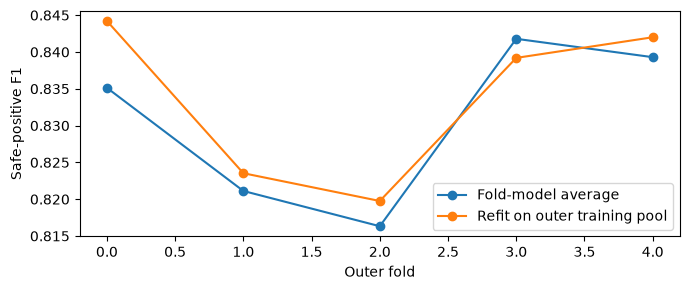

In [3]:
probe=json.loads((DEST/'strict_refit_probe.json').read_text())
print('검증 행:',probe['hold_rows'],'outer folds:',probe.get('outer_folds',1))
display(pd.DataFrame({n:{k:probe[n][k] for k in ['auc','f1','accuracy']} for n in ['fold_average','refit','half_refit_half_cv']}).T)
print('Paired F1 difference 95% interval:',probe['paired_refit_f1_difference_interval_95'])
fold_reports=probe.get('fold_reports',[probe])
display(pd.DataFrame([{'fold':k,'cv_f1':q['fold_average']['f1'],'refit_f1':q['refit']['f1'],'mix_f1':q['half_refit_half_cv']['f1']} for k,q in enumerate(fold_reports)]))
assert all('Earlier global tuning' in q['hyperparameter_selection_caveat'] for q in fold_reports)
fig,ax=plt.subplots(figsize=(7,3))
ax.plot([q['fold_average']['f1'] for q in fold_reports],marker='o',label='Fold-model average')
ax.plot([q['refit']['f1'] for q in fold_reports],marker='o',label='Refit on outer training pool')
ax.set(xlabel='Outer fold',ylabel='Safe-positive F1');ax.legend();plt.tight_layout();plt.show()

## 3. ChemBERTa 미세조정과 SMILES 강화

기존 실험은 고정 임베딩 위의 SVM/LGBM이었다. 새 실험은 마지막 encoder 층과 분류 head를 독성 라벨로 학습했다. 짧은 8-epoch 실험과 랜덤 SMILES/TTA/24-epoch 강화 실험을 구분한다.

강화 실험은 마지막 3개 epoch 예측을 평균하며 검증 AUC로 epoch를 선택하지 않는다. 랜덤 SMILES의 stereo canonical round-trip이 달라지는 표현은 원문으로 대체한다. 모델이 학습에 쓰는 표현만 달라지고 제출 SMILES는 그대로다.

chemberta_finetuned OOF AUC: 0.7958321636763351
chemberta_augmented OOF AUC: 0.8452712950731445
증강 검증: {'views': 4, 'molecules': 9276, 'rejected_random_views': 2, 'stereo_canonical_preserved': True}
강화 모델 메타 비교: {
  "base_bert_auc": 0.8452712950731445,
  "stack_auc": 0.8946818284286392,
  "seed_f1": [
    0.833072345756342,
    0.8360980699008868,
    0.8344978621336948
  ],
  "baseline_seed_f1": [
    0.8341898269533299,
    0.835103060587133,
    0.8341560760424325
  ],
  "repeated_cross_threshold_f1": 0.8345560925969746,
  "gain": 7.310473600952161e-05,
  "band_auc_gain": -0.001293371471210003,
  "paired_f1_gain_interval_95": [
    -0.0013724090175433329,
    0.0014972969940644702
  ],
  "adopt": false,
  "predeclared_gate": "mean F1 gain>=.001, nonnegative in every seed, band AUC gain>=.002",
  "scope": "Meta CV reuses base OOF; indirect leakage and prior global parameter selection remain."
}


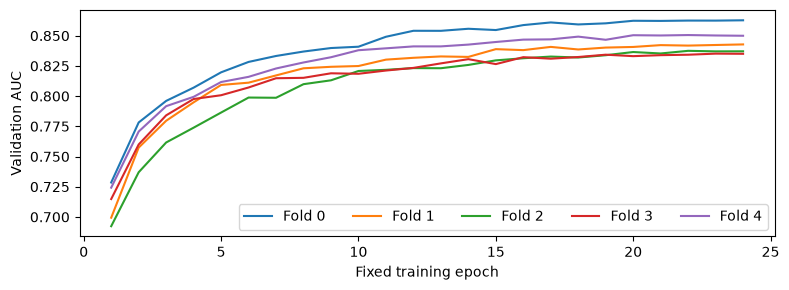

In [4]:
y=np.load(ROOT/'07_개선/features.npz',allow_pickle=True)['y'].astype(int)
for name in ['chemberta_finetuned','chemberta_augmented']:
 z=np.load(DEST/f'{name}.npz');print(name,'OOF AUC:',roc_auc_score(y,z['oof']))
print('증강 검증:',json.loads((DEST/'chemberta_aug/augmentation_validation.json').read_text()))
augmentation=json.loads((DEST/'augmentation_meta.json').read_text())
print('강화 모델 메타 비교:',json.dumps(augmentation,ensure_ascii=False,indent=2))
fig,ax=plt.subplots(figsize=(8,3))
for k in range(5):
 history=json.loads((DEST/f'chemberta_aug/fold{k}.json').read_text())['history']
 ax.plot([q['epoch'] for q in history],[q['valid_auc'] for q in history],label=f'Fold {k}')
ax.set(xlabel='Fixed training epoch',ylabel='Validation AUC');ax.legend(ncol=5);plt.tight_layout();plt.show()

## 4. 확률 기반 융합·전량 재학습과 927행 예측

실제 최고 제출본(리더보드 0.8393)의 20개 입력에 Chemprop·CatBoost·Mordred·ChemBERTa/MoLFormer SVM을 추가했다. 순위 대신 확률의 logit을 합치며 3-seed × 5-fold 로지스틱 예측을 평균한다. 각 base 모델은 전체 8,349행으로도 재학습했다. 기존 OOF는 새 숨은 데이터 점수가 아니다. 임계값은 inner meta CV에서 얻은 중앙값으로 고정했다. A=493과 보정된 확률로 계산한 기대 F1 곡선은 참고용이며 임계값 선택에 쓰지 않았다. 실측 리더보드 점수도 아니다.

전량 재학습 비중은 사전에 고정한 outer 평가 기준으로 골랐다. 숨은 테스트에서 가장 좋은 비중을 선택한 것이 아니다.

,name,width,C,auc,f1,seed_f1,cut,band_auc
0,best20,20,0.10,0.895499,0.833391,"[0.8340937370385733, 0.8320182724252492, 0.834...",0.404347,0.549188
1,plus_cp,21,0.10,0.896374,0.834634,"[0.8346440180350215, 0.8344647519582246, 0.834...",0.418542,0.559077
2,plus_three,23,0.10,0.896428,0.835229,"[0.8367003367003367, 0.8346045345313969, 0.834...",0.428499,0.560247
3,plus_five,25,0.10,0.896314,0.835438,"[0.8366341821230221, 0.8344149047519364, 0.835...",0.421868,0.561837
4,plus_five_reg,25,0.03,0.896450,0.834742,"[0.8356394129979036, 0.8345746354767649, 0.834...",0.424137,0.560549


반복 meta CV 개선 구간: [-0.00010384419713492243, 0.004227429991444467]
간접 누수/모델 선택 편향 때문에 독립 성능 추정치로 볼 수 없습니다.
5-fold nested-fitting proxy refit F1 gain=0.002966; full at >=.003, half in [-.002,.003), otherwise CV. Proxy uses 3 families, not final 25.


,full_data_fraction,D,threshold,estimated_f1_not_measured,changed_from_current,changed_from_best_actual_submission,file
0,0.0,556,0.421868,0.834517,11,15,predict_output_finalmix_0.csv
1,0.5,557,0.421868,0.838506,10,14,predict_output_finalmix_0.5.csv
2,1.0,551,0.421868,0.842992,18,22,predict_output_finalmix_1.csv


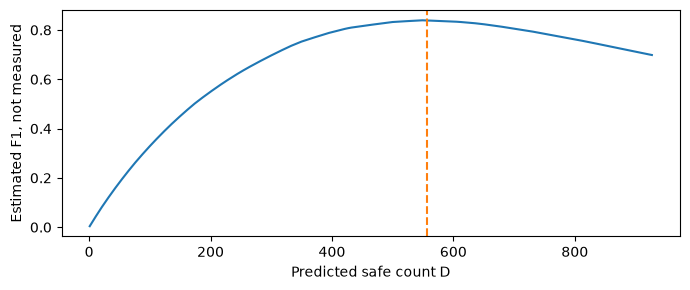

In [5]:
fusion=json.loads((DEST/'probability_fusion.json').read_text())
display(pd.DataFrame(fusion['candidates']))
print('반복 meta CV 개선 구간:',fusion['paired_gain_interval_95'])
print('간접 누수/모델 선택 편향 때문에 독립 성능 추정치로 볼 수 없습니다.')
print(selection['choice_reason'])
display(pd.DataFrame(selection['candidates']))
selected=selection['selected']
score_path=DEST/f"final_scores_{selected['full_data_fraction']:g}.npz"
scores=np.load(score_path)
fig,ax=plt.subplots(figsize=(7,3))
ax.plot(np.arange(1,928),scores['estimated_f1_curve']);ax.axvline(selected['D'],color='C1',ls='--')
ax.set(xlabel='Predicted safe count D',ylabel='Estimated F1, not measured');plt.tight_layout();plt.show()

## 5. 제출 파일 형식과 보존 검사

`output=1`은 비독성이고 0은 독성이다. 927행·칼럼명·SMILES 원문/순서·0/1 값과 기존 파일 보존을 확인한다. 별도 제출용 파일이며 현재 3차 루트 Output을 덮어쓰지 않는다.

In [6]:
template=pd.read_csv(ROOT/'01_원본자료/predict_output_홍길동.csv')
current=pd.read_csv(ROOT/'predict_output_서혁인.csv')
submission=pd.read_csv(DEST/'제출용/predict_output_서혁인.csv')
assert list(submission)==list(template)==['SMILES','output'] and submission.shape==(927,2)
assert submission.SMILES.equals(template.SMILES) and submission.SMILES.equals(current.SMILES)
assert set(submission.output)<={0,1} and submission.output.sum()==selected['D']
assert hashlib.sha256((DEST/'제출용/predict_output_서혁인.csv').read_bytes()).hexdigest()==validation['submission_sha256']
assert int((submission.output!=current.output).sum())==selected['changed_from_current']
print('PASS: 데이터 형식·SMILES·예측·해시·기존 파일 보존')
display(submission.output.value_counts().rename('rows'))
display(pd.read_csv(DEST/'changed_predictions.csv'))
print('제출하지 않았습니다.')

PASS: 데이터 형식·SMILES·예측·해시·기존 파일 보존


output
1    557
0    370
Name: rows, dtype: int64

,row_1based,SMILES,previous_output,best_actual_submission_output,candidate_output,safe_score,calibrated_estimate
0,54,COC(=O)[C@H]1[C@H](C[C@@H]2CC[C@H]1N2C)OC(=O)c...,1,0,0,0.317678,0.357081
1,181,CNCc1cc(ccc1Oc2ccc(Cl)c(Cl)c2)S(=O)(=O)NC,1,1,0,0.386505,0.369315
2,241,Nc1ccccc1NC(=O)c2ccc(cc2)c3ncc(CN4CCC4)cc3Cl,1,0,0,0.327583,0.357081
3,285,CN(C(=O)C)c1ccc(OC2CN(C2)c3c4CCNCCc4nc5ccnn35)cc1,1,0,0,0.404039,0.369315
4,322,ONC(=O)\C=C\c1ccc(CNCCc2c([nH]c3ccccc23)c4cccs...,1,0,0,0.418425,0.369315
5,393,CCN(CC)Cc1ccc2C[C@H](CCc2c1)N3CCN(CCc4ccc(F)cc...,1,0,0,0.406391,0.369315
6,399,O=C1OCCN1C2CCN(CCOc3ccc(Oc4nc5ccccc5s4)cc3)CC2,1,1,0,0.404875,0.369315
7,495,COc1ccc(cc1Nc2ncc(Cl)c(n2)c3cnc4ccccn34)C(=O)N...,1,0,0,0.343407,0.357081
8,754,COc1cccc(\C=C\c2ccc(cc2)C(=O)Nc3cc(C(=O)Nc4cc(...,1,1,0,0.415686,0.369315
9,914,C\C(=N/C(=N\S(=O)(=O)c1ccc(Cl)cc1)/N2C[C@@H](C...,1,0,0,0.403516,0.369315


제출하지 않았습니다.


## 재현

작업공간 `.venv_eda`를 사용한다. `10_최종개선/full_refit.py tabular`, `extra`, `chemprop`은 전체 학습을 수행한다. `run_remaining_probes.py`와 `aggregate_probes.py`는 외부 분할 실험을 재현한다. `chemberta_finetune.py cv`와 `CB_AUGMENT=1 ... cv`는 GPU로 긴 미세조정을 실행한다. `augmentation_meta.py`는 추가 모델 기여를 검증한다. `best_score_refit.py`는 기존 최고 제출본의 전체 학습 예측을, `probability_fusion.py`는 추가 조합의 반복 메타 검증을, `finalize_best.py`는 최종 후보를 재현한다. 모두 외부 제출하지 않는다.

[결과 보고서](../10_최종개선/개선_결과.md) · [실험 계획](../10_최종개선/실험계획.md)